

Rice Leaf Disease Detection Using Deep Learning

Project ID: PRCP-1001

Project Overview

Rice is one of the most important food crops worldwide. However, rice plants are affected by various diseases that can reduce crop quality and production. Early identification of these diseases is important for effective disease management.

This project aims to develop a deep learning-based image classification system that can identify rice leaf diseases from images. The project uses different deep learning models to classify rice leaves into three disease categories:

* Bacterial Leaf Blight
* Brown Spot
* Leaf Smut

The performance of different models, including Custom CNN, MobileNetV2, ResNet50, and EfficientNetB0, is evaluated and compared to identify the best-performing model.

Project Objectives

1. Analyze and understand the rice leaf disease dataset.
2. Perform image preprocessing and data augmentation.
3. Develop deep learning models for disease classification.
4. Compare the performance of different models.
5. Identify the best-performing model.
6. Develop a system to predict rice leaf diseases from uploaded images.


In [11]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# 2. Import Libraries

In [12]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

print("Libraries imported successfully!")

Libraries imported successfully!


3. Dataset Description

The dataset used in this project contains images of rice leaves affected by different diseases. It is used to train and evaluate deep learning models for automated disease classification.

The dataset consists of three disease categories:

* Bacterial Leaf Blight
* Brown Spot
* Leaf Smut

Each image represents a rice leaf affected by one of the diseases. The dataset is used to develop an image classification system that can identify the disease category from a leaf image.

Dataset Information

Parameter	Description
Dataset Name	Rice Leaf Disease Dataset
Total Images	119 images (available in our dataset)
Number of Classes	3
Image Format	JPG
Task	Image Classification
Domain	Agriculture
Classes	Bacterial Leaf Blight, Brown Spot, Leaf Smut

Dataset Distribution

The dataset contains approximately 40 images for each disease class. This relatively small dataset makes data augmentation and transfer learning useful techniques for improving model learning.

# 4. Data Loading

In [14]:
dataset_path = "/content/drive/MyDrive/Rice_Leaf_Disease_Detection/Dataset"
data_path = dataset_path + "/Data"

In [15]:
disease_folders = [
    "Bacterial leaf blight-20200814T055237Z-001/Bacterial leaf blight",
    "Brown spot-20200814T055208Z-001/Brown spot",
    "Leaf smut-20200814T055530Z-001/Leaf smut"
]

In [16]:
bacterial_images = os.listdir(data_path + "/" + disease_folders[0])
brown_spot_images = os.listdir(data_path + "/" + disease_folders[1])
leaf_smut_images = os.listdir(data_path + "/" + disease_folders[2])

print("Bacterial Leaf Blight:", len(bacterial_images))

print("Brown Spot:", len(brown_spot_images))

print("Leaf Smut:", len(leaf_smut_images))

Bacterial Leaf Blight: 40
Brown Spot: 40
Leaf Smut: 39


# 5. Exploratory Data Analysis (EDA)


Exploratory Data Analysis (EDA) was performed to understand the dataset, examine the distribution of disease classes, visualize sample images, and analyze the image characteristics.

The analysis helps identify the dataset structure, class distribution, image dimensions, and potential challenges before training the deep learning models.

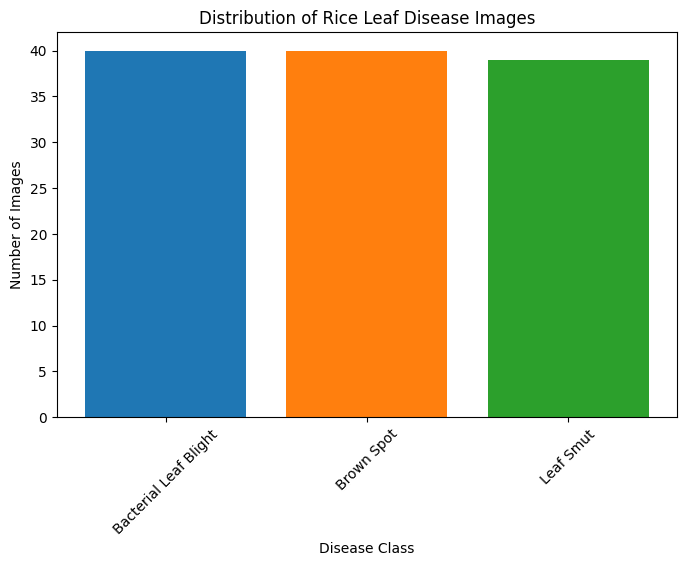

In [18]:
import matplotlib.pyplot as plt
import numpy as np

classes = ['Bacterial Leaf Blight', 'Brown Spot', 'Leaf Smut']
counts = [len(bacterial_images), len(brown_spot_images), len(leaf_smut_images)]

plt.figure(figsize=(8, 5))
plt.bar(classes, counts, color=['#1f77b4', '#ff7f0e', '#2ca02c'])

plt.title("Distribution of Rice Leaf Disease Images")
plt.xlabel("Disease Class")
plt.ylabel("Number of Images")

plt.xticks(rotation=45)
plt.show()

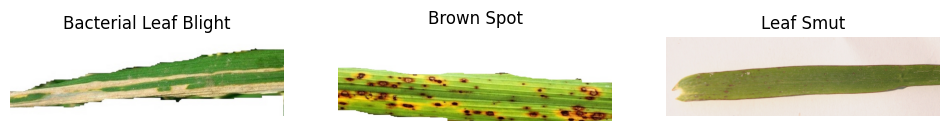

In [19]:
plt.figure(figsize=(12, 6))

for i in range(3):

    if i == 0:
        images = bacterial_images
        disease_name = "Bacterial Leaf Blight"
        folder = disease_folders[0]

    elif i == 1:
        images = brown_spot_images
        disease_name = "Brown Spot"
        folder = disease_folders[1]

    else:
        images = leaf_smut_images
        disease_name = "Leaf Smut"
        folder = disease_folders[2]

    image_path = data_path + "/" + folder + "/" + images[0]
    img = plt.imread(image_path)

    plt.subplot(1, 3, i + 1)
    plt.imshow(img)
    plt.title(disease_name)
    plt.axis("off")

plt.show()

In [20]:
df = pd.DataFrame()

df["Disease"] = ["Bacterial leaf blight", "Brown spot", "Leaf smut"]

df["Number of Images"] = [
    len(bacterial_images),
    len(brown_spot_images),
    len(leaf_smut_images)
]

df

,Disease,Number of Images
0,Bacterial leaf blight,40
1,Brown spot,40
2,Leaf smut,39


In [22]:
import cv2
import os

for folder in disease_folders:

    folder_path = data_path + "/" + folder

    for image_name in os.listdir(folder_path):

        image_path = folder_path + "/" + image_name

        img = cv2.imread(image_path)

        if img is not None:

            print(img.shape[:2])

(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(250, 766)
(193, 427)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(514, 768)
(371, 1530)
(897, 3081)
(897, 3081)
(244, 617)
(224, 765)
(92, 286)
(94, 340)
(197, 699)
(897, 3081)
(88, 296)
(897, 3081)
(168, 359)
(897, 3081)
(897, 3081)
(897, 3081)
(897, 3081)
(900, 1200)
(323, 1504)
(897, 3081)
(897, 3081)
(127, 316)
(268, 763)
(897, 3081)
(897, 3081)
(897, 3081)
(279, 1480)
(897, 3081)
(897, 3081)
(104, 467)
(124, 456)
(897, 3081)
(897, 3081)
(170, 311)
(897, 3081)
(200, 250)
(217, 562)
(216, 537)
(897, 3081)
(

In [23]:
corrupted_images = []

for folder in disease_folders:
    folder_path = data_path + "/" + folder

    for image_name in os.listdir(folder_path):
        image_path = folder_path + "/" + image_name

        img = cv2.imread(image_path)

        if img is None:
            corrupted_images.append(image_name)

print("Corrupted images:", len(corrupted_images))

Corrupted images: 0


In [24]:
df = pd.DataFrame()

df["Disease"] = ["Bacterial leaf blight", "Brown spot", "Leaf smut"]

df["Number of Images"] = [
    len(bacterial_images),
    len(brown_spot_images),
    len(leaf_smut_images)
]

df

,Disease,Number of Images
0,Bacterial leaf blight,40
1,Brown spot,40
2,Leaf smut,39


In [25]:
total_images = df["Number of Images"].sum()
df["Percentage"] = (df["Number of Images"] / total_images) * 100
df["Percentage"] = df["Percentage"].round(2)
df

,Disease,Number of Images,Percentage
0,Bacterial leaf blight,40,33.61
1,Brown spot,40,33.61
2,Leaf smut,39,32.77


In [26]:
df.describe()

,Number of Images,Percentage
count,3.000000,3.000000
mean,39.666667,33.330000
std,0.577350,0.484974
min,39.000000,32.770000
25%,39.500000,33.190000
50%,40.000000,33.610000
75%,40.000000,33.610000
max,40.000000,33.610000


In [27]:
img = cv2.imread(image_path)

print("Image shape:", img.shape)

Image shape: (897, 3081, 3)


In [28]:
image_names = []
image_dimensions = []

for folder in disease_folders:

    folder_path = data_path + "/" + folder

    for image_name in os.listdir(folder_path):

        image_path = folder_path + "/" + image_name

        image = cv2.imread(image_path)

        image_names.append(image_name)
        image_dimensions.append(image.shape)

print("Total images:", len(image_names))

Total images: 119


In [29]:
image_df = pd.DataFrame({
    "Image_Name": image_names,
    "Dimensions": image_dimensions
})

In [30]:
image_df["Dimensions"].unique()

array([(897, 3081, 3), (250, 766, 3), (193, 427, 3), (514, 768, 3),
       (371, 1530, 3), (244, 617, 3), (224, 765, 3), (92, 286, 3),
       (94, 340, 3), (197, 699, 3), (88, 296, 3), (168, 359, 3),
       (900, 1200, 3), (323, 1504, 3), (127, 316, 3), (268, 763, 3),
       (279, 1480, 3), (104, 467, 3), (124, 456, 3), (170, 311, 3),
       (200, 250, 3), (217, 562, 3), (216, 537, 3), (233, 948, 3),
       (409, 614, 3), (71, 301, 3), (291, 741, 3), (174, 503, 3),
       (73, 367, 3), (255, 946, 3), (211, 948, 3), (80, 376, 3),
       (383, 510, 3), (233, 565, 3)], dtype=object)

## 6. Data Preprocessing

Data preprocessing is an important step in preparing images for deep learning models. In this project, images are resized to a fixed dimension of 224 × 224 pixels, converted into numerical arrays, and prepared for model training. Pixel values are normalized to improve the learning process. The dataset is also divided into training, validation, and testing sets.

In [31]:
import cv2
import numpy as np
import os

X_resized = []
labels = []

img_height = 224
img_width = 224

for folder in disease_folders:

    folder_path = os.path.join(data_path, folder)

    disease_name = folder.split("/")[-1]

    for image_name in os.listdir(folder_path):

        image_path = os.path.join(folder_path, image_name)

        image = cv2.imread(image_path)

        if image is None:
            continue

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (img_width, img_height))

        X_resized.append(image)
        labels.append(disease_name)

X_resized = np.array(X_resized)
labels = np.array(labels)

print("Images shape:", X_resized.shape)
print("Labels shape:", labels.shape)

Images shape: (119, 224, 224, 3)
Labels shape: (119,)


In [32]:
X = X_resized
y = labels

print(X.shape)
print(y.shape)

(119, 224, 224, 3)
(119,)


In [33]:
import numpy as np

X_resized = np.array(X_resized)

print(X_resized.shape)

(119, 224, 224, 3)


In [34]:
labels = []

for folder in disease_folders:
    folder_path = data_path + "/" + folder

    for image_name in os.listdir(folder_path):
        labels.append(folder)

In [35]:
from sklearn.preprocessing import LabelEncoder
import numpy as np

le = LabelEncoder()
y = le.fit_transform(labels)

print("Total labels:", len(y))
print("Class distribution:", np.bincount(y))
print("Class mappings:", dict(zip(le.classes_, le.transform(le.classes_))))

Total labels: 119
Class distribution: [40 40 39]
Class mappings: {np.str_('Bacterial leaf blight-20200814T055237Z-001/Bacterial leaf blight'): np.int64(0), np.str_('Brown spot-20200814T055208Z-001/Brown spot'): np.int64(1), np.str_('Leaf smut-20200814T055530Z-001/Leaf smut'): np.int64(2)}


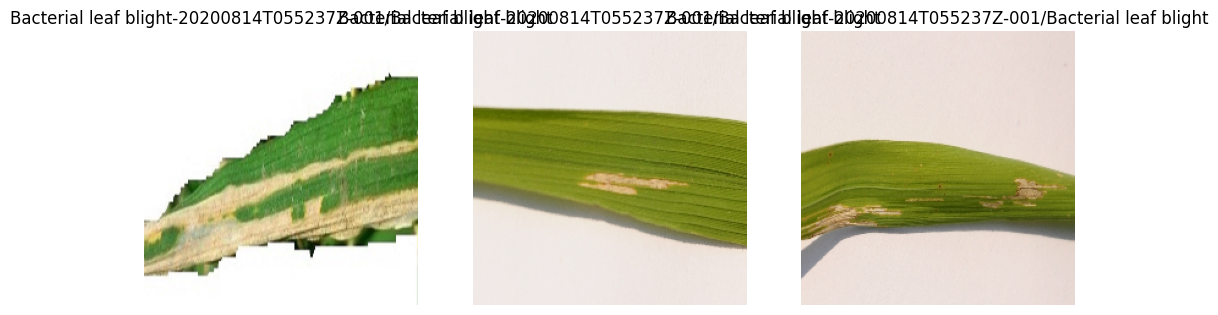

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(X_resized[i])
    plt.title(le.classes_[y[i]])
    plt.axis("off")

plt.show()

In [37]:
print("Images:", len(X_resized))
print("Labels:", len(labels))

Images: 119
Labels: 119


In [38]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y = le.fit_transform(labels)

print(len(y))

119


In [39]:
print("Images:", len(X_resized))
print("Labels:", len(labels))

Images: 119
Labels: 119


In [40]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

y = le.fit_transform(labels)

In [41]:
print("Number of labels:", len(y))
print("Classes:", le.classes_)

Number of labels: 119
Classes: ['Bacterial leaf blight-20200814T055237Z-001/Bacterial leaf blight'
 'Brown spot-20200814T055208Z-001/Brown spot'
 'Leaf smut-20200814T055530Z-001/Leaf smut']


In [42]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_resized,
    y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.1765,
    random_state=42,
    stratify=y_train
)

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

Training: 83
Validation: 18
Testing: 18


## 7. Data Augmentation

Data augmentation is used to artificially increase the diversity of training images by applying transformations such as rotation, flipping, zooming, shifting, and brightness adjustments. These transformations help the model learn different variations of images and may improve its ability to generalize to unseen data.

In [44]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=15,
    horizontal_flip=True,
    zoom_range=0.10,
    width_shift_range=0.05,
    height_shift_range=0.05,
    brightness_range=[0.9, 1.1]
)

In [45]:
augmented_data = datagen.flow(
    X_train,
    y_train,
    batch_size=16,
    shuffle=True
)

In [46]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

X_train = preprocess_input(X_train)
X_val = preprocess_input(X_val)
X_test = preprocess_input(X_test)

In [47]:
print("Training:", X_train.min(), X_train.max())
print("Validation:", X_val.min(), X_val.max())
print("Testing:", X_test.min(), X_test.max())

Training: -1.0 1.0
Validation: -1.0 1.0
Testing: -1.0 1.0


## 8. MobileNetV2 Model

MobileNetV2 is a lightweight and efficient convolutional neural network architecture designed for image classification. It uses depthwise separable convolutions and inverted residual blocks to reduce computational complexity while maintaining good performance.

In this project, MobileNetV2 is used with transfer learning to classify rice leaf diseases into three categories: Bacterial Leaf Blight, Brown Spot, and Leaf Smut.

In [128]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dropout, Dense
from tensorflow.keras.models import Model

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.4)(x)
x = Dense(128, activation="relu")(x)
x = Dropout(0.3)(x)

output = Dense(3, activation="softmax")(x)

model = Model(inputs=base_model.input, outputs=output)

In [129]:
from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [130]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=1e-7,
    verbose=1
)

In [131]:
history = model.fit(
    augmented_data,
    validation_data=(X_val, y_val),
    epochs=40,
    callbacks=[early_stop, reduce_lr]
)

Epoch 1/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 14s 2s/step - accuracy: 0.3494 - loss: 1.3929 - val_accuracy: 0.4444 - val_loss: 1.2245 - learning_rate: 1.0000e-04
Epoch 2/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.4217 - loss: 1.3426 - val_accuracy: 0.6111 - val_loss: 1.0990 - learning_rate: 1.0000e-04
Epoch 3/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.4217 - loss: 1.3713 - val_accuracy: 0.6111 - val_loss: 1.0048 - learning_rate: 1.0000e-04
Epoch 4/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step - accuracy: 0.5663 - loss: 1.1218 - val_accuracy: 0.6667 - val_loss: 0.9336 - learning_rate: 1.0000e-04
Epoch 5/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 954ms/step - accuracy: 0.4940 - loss: 1.0921 - val_accuracy: 0.6111 - val_loss: 0.8827 - learning_rate: 1.0000e-04
Epoch 6/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.6265 - loss: 0.8309 - val_accuracy: 0.6667 - val_loss: 0.8255 - learning_rate: 1.0000e-04
Epoch 7/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.5422 - loss: 0.9332 - val_acc

In [132]:
model.evaluate(X_test, y_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 982ms/step - accuracy: 0.8889 - loss: 0.3284


[0.3283784091472626, 0.8888888955116272]

1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step


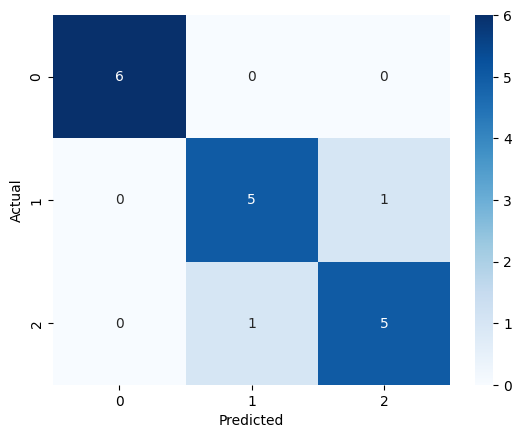

In [133]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

y_pred = model.predict(X_test).argmax(axis=1)

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [134]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, target_names=le.classes_))

                       precision    recall  f1-score   support

Bacterial leaf blight       1.00      1.00      1.00         6
           Brown spot       0.83      0.83      0.83         6
            Leaf smut       0.83      0.83      0.83         6

             accuracy                           0.89        18
            macro avg       0.89      0.89      0.89        18
         weighted avg       0.89      0.89      0.89        18



Saving DSC_0366.jpg to DSC_0366 (1).jpg


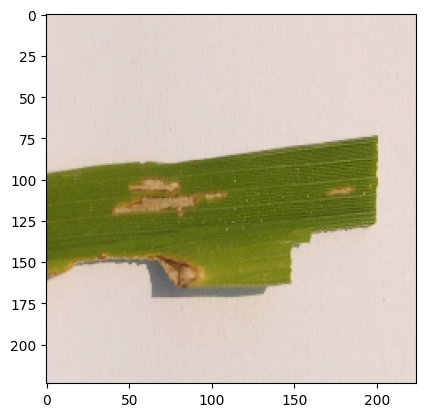

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step
Predicted Disease: Bacterial leaf blight-20200814T055237Z-001/Bacterial leaf blight


In [121]:
from google.colab import files
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()

img_path = list(uploaded.keys())[0]

img = image.load_img(img_path, target_size=(224, 224))
plt.imshow(img)
plt.show()

img = image.img_to_array(img)
img = np.expand_dims(img, axis=0)
img = preprocess_input(img)

prediction = model.predict(img)

print("Predicted Disease:", le.classes_[np.argmax(prediction)])

In [186]:
print(model)

<Functional name=functional_5, built=True>


In [188]:
model.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_5[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,751,051 (10.49 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

 Optimizer params: 328,712 (1.25 MB)

In [85]:
model.save("mobilenetv2_normal.keras")

In [194]:
from sklearn.metrics import classification_report

y_pred_mobilenet = model.predict(X_test)
y_pred_mobilenet = y_pred_mobilenet.argmax(axis=1)

print("MobileNetV2 Classification Report")
print(classification_report(
    y_test,
    y_pred_mobilenet,
    target_names=le.classes_
))

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
MobileNetV2 Classification Report
                       precision    recall  f1-score   support

Bacterial leaf blight       1.00      1.00      1.00         6
           Brown spot       0.83      0.83      0.83         6
            Leaf smut       0.83      0.83      0.83         6

             accuracy                           0.89        18
            macro avg       0.89      0.89      0.89        18
         weighted avg       0.89      0.89      0.89        18



In [92]:
import os

print(os.path.exists("mobilenetv2_normal.keras"))

True


In [93]:
import shutil

destination = "/content/drive/MyDrive/Rice_Leaf_Disease_Detection/mobilenetv2_normal.keras"

shutil.copy("mobilenetv2_normal.keras", destination)

print("Model saved successfully to Google Drive!")

Model saved successfully to Google Drive!


## 10. ResNet50 Model

ResNet50 is a deep convolutional neural network architecture that uses residual connections (skip connections) to help overcome the vanishing gradient problem and enable the training of deeper networks.

In this project, ResNet50 is used with transfer learning to classify rice leaf diseases into three categories: Bacterial Leaf Blight, Brown Spot, and Leaf Smut.

In [48]:
from tensorflow.keras.applications import ResNet50

base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

print("ResNet50 loaded successfully!")

ResNet50 loaded successfully!


In [49]:
base_model.trainable = False

print("ResNet50 layers frozen!")

ResNet50 layers frozen!


In [50]:
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model

x = base_model.output

x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
output = Dense(3, activation="softmax")(x)

resnet_model = Model(inputs=base_model.input, outputs=output)

print("ResNet50 model created successfully!")

ResNet50 model created successfully!


In [51]:
resnet_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [52]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    patience=3,
    factor=0.2
)

print("Callbacks created successfully!")

Callbacks created successfully!


In [55]:
history_resnet = resnet_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size = 16,
    callbacks=[early_stop, reduce_lr]
)

Epoch 1/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 24s 4s/step - accuracy: 0.5422 - loss: 0.9466 - val_accuracy: 0.5556 - val_loss: 1.0039 - learning_rate: 2.0000e-04
Epoch 2/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 36s 3s/step - accuracy: 0.5301 - loss: 0.9867 - val_accuracy: 0.5000 - val_loss: 1.0029 - learning_rate: 2.0000e-04
Epoch 3/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 17s 3s/step - accuracy: 0.4940 - loss: 0.9935 - val_accuracy: 0.5556 - val_loss: 1.0023 - learning_rate: 2.0000e-04
Epoch 4/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 21s 3s/step - accuracy: 0.5422 - loss: 0.9537 - val_accuracy: 0.5556 - val_loss: 1.0023 - learning_rate: 2.0000e-04
Epoch 5/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 19s 3s/step - accuracy: 0.4337 - loss: 0.9958 - val_accuracy: 0.5000 - val_loss: 1.0014 - learning_rate: 2.0000e-04
Epoch 6/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 19s 3s/step - accuracy: 0.4940 - loss: 1.0166 - val_accuracy: 0.3889 - val_loss: 1.0009 - learning_rate: 2.0000e-04
Epoch 7/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 20s 3s/step - accuracy: 0.5181 - loss: 0.9426 - val_

In [61]:
resnet_model.evaluate(X_test, y_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.4444 - loss: 1.0833


[1.083348274230957, 0.4444444477558136]

In [62]:
from sklearn.metrics import classification_report

y_pred_resnet = resnet_model.predict(X_test)
y_pred_resnet = y_pred_resnet.argmax(axis=1)

print("ResNet50 - Without Fine-Tuning")

print(classification_report(
    y_test,
    y_pred_resnet,
    target_names=le.classes_
))

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
ResNet50 - Without Fine-Tuning
                                                                  precision    recall  f1-score   support

Bacterial leaf blight-20200814T055237Z-001/Bacterial leaf blight       0.50      0.50      0.50         6
                      Brown spot-20200814T055208Z-001/Brown spot       1.00      0.17      0.29         6
                        Leaf smut-20200814T055530Z-001/Leaf smut       0.36      0.67      0.47         6

                                                        accuracy                           0.44        18
                                                       macro avg       0.62      0.44      0.42        18
                                                    weighted avg       0.62      0.44      0.42        18



1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


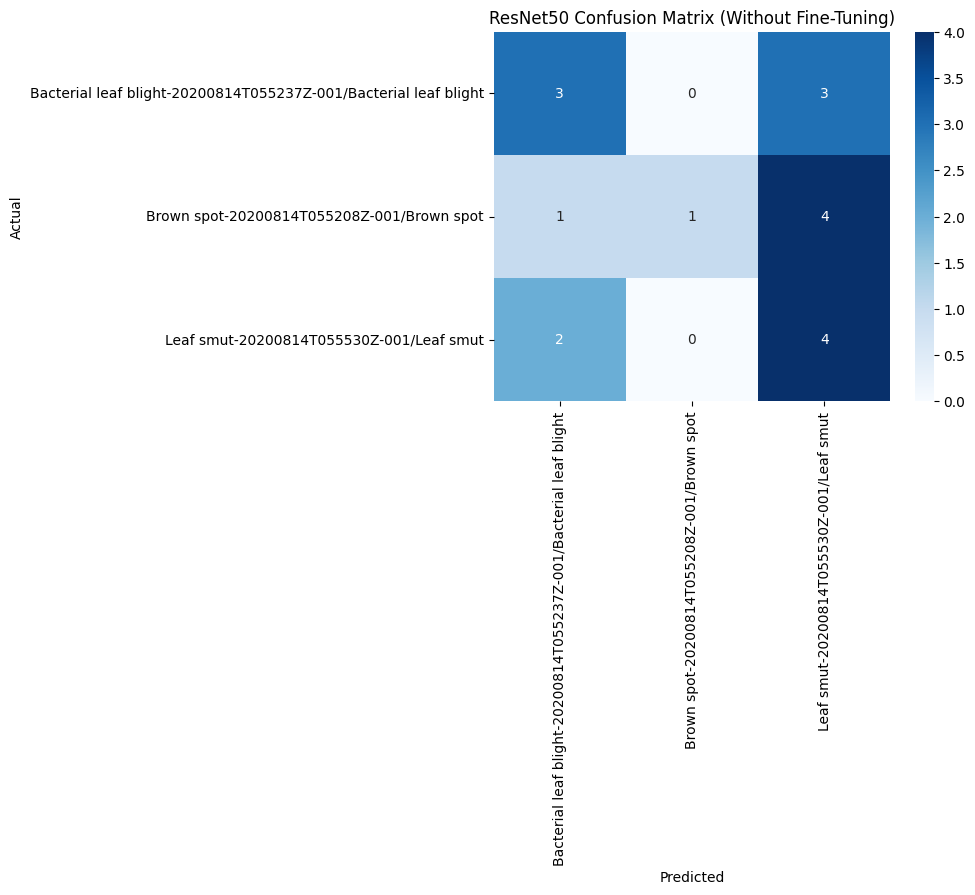

In [63]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

y_pred = resnet_model.predict(X_test).argmax(axis=1)

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=le.classes_,
            yticklabels=le.classes_)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("ResNet50 Confusion Matrix (Without Fine-Tuning)")
plt.show()

In [64]:
resnet_model.save("resnet50_normal.keras")

In [66]:
import shutil

destination = "/content/drive/MyDrive/Rice_Leaf_Disease_Detection/resnet50_normal.keras"

shutil.copy("resnet50_normal.keras", destination)

print("ResNet50 model saved successfully to Google Drive!")

ResNet50 model saved successfully to Google Drive!


FINE-TUNED RESNET


In [77]:
base_model.trainable = True

for layer in base_model.layers[:-20]:
    layer.trainable = False

In [80]:
from tensorflow.keras.optimizers import Adam

resnet_model.compile(
    optimizer=Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [147]:
history_fine = resnet_model.fit(
    augmented_data,
    validation_data=(X_val, y_val),
    epochs=15,
    callbacks=[early_stop, reduce_lr]
)

Epoch 1/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 28s 5s/step - accuracy: 0.5060 - loss: 0.9044 - val_accuracy: 0.5000 - val_loss: 0.9847 - learning_rate: 2.0000e-06
Epoch 2/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 52s 7s/step - accuracy: 0.6024 - loss: 0.8777 - val_accuracy: 0.4444 - val_loss: 0.9894 - learning_rate: 2.0000e-06
Epoch 3/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 29s 6s/step - accuracy: 0.6867 - loss: 0.7748 - val_accuracy: 0.4444 - val_loss: 0.9931 - learning_rate: 2.0000e-06
Epoch 4/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 30s 5s/step - accuracy: 0.5904 - loss: 0.8360 - val_accuracy: 0.3889 - val_loss: 0.9977 - learning_rate: 4.0000e-07
Epoch 5/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 31s 5s/step - accuracy: 0.6506 - loss: 0.8307 - val_accuracy: 0.3889 - val_loss: 1.0030 - learning_rate: 4.0000e-07


In [84]:
import tensorflow as tf
model_path = "resnet50_finetuned.keras"
model = tf.keras.models.load_model(model_path)


model.evaluate(X_test, y_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step - accuracy: 0.4444 - loss: 1.0833


[1.083348274230957, 0.4444444477558136]

In [198]:
from sklearn.metrics import classification_report

y_pred_resnet_fine = resnet_model.predict(X_test)
y_pred_resnet_fine = y_pred_resnet_fine.argmax(axis=1)

print("ResNet50 - Fine-Tuned Classification Report")

print(classification_report(
    y_test,
    y_pred_resnet_fine,
    target_names=le.classes_
))

1/1 ━━━━━━━━━━━━━━━━━━━━ 10s 10s/step
ResNet50 - Fine-Tuned Classification Report
                       precision    recall  f1-score   support

Bacterial leaf blight       0.00      0.00      0.00         6
           Brown spot       1.00      0.17      0.29         6
            Leaf smut       0.35      1.00      0.52         6

             accuracy                           0.39        18
            macro avg       0.45      0.39      0.27        18
         weighted avg       0.45      0.39      0.27        18



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


1/1 ━━━━━━━━━━━━━━━━━━━━ 13s 13s/step


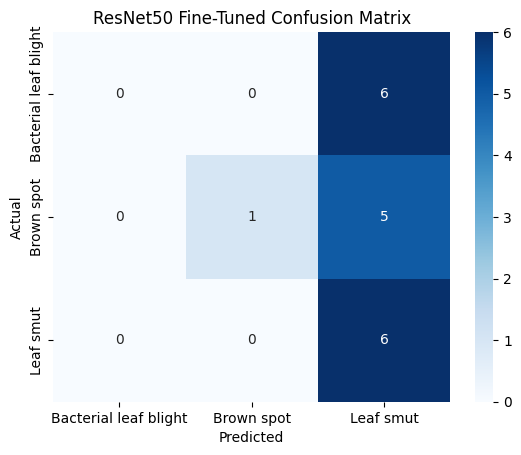

In [155]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

y_pred = resnet_model.predict(X_test).argmax(axis=1)

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=le.classes_,
            yticklabels=le.classes_)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("ResNet50 Fine-Tuned Confusion Matrix")
plt.show()

In [74]:
resnet_model.save("resnet50_finetuned.keras")

In [86]:
import shutil

destination = "/content/drive/MyDrive/Rice_Leaf_Disease_Detection/resnet50_finetuned.keras"

shutil.copy("resnet50_finetuned.keras", destination)

print("Model saved successfully to Google Drive!")

Model saved successfully to Google Drive!


## 11. EfficientNetB0 Model

EfficientNetB0 is a convolutional neural network architecture that balances model accuracy and computational efficiency. It uses compound scaling to efficiently scale network depth, width, and resolution.

In this project, EfficientNetB0 is used with transfer learning to classify rice leaf diseases into three categories: Bacterial Leaf Blight, Brown Spot, and Leaf Smut.

In [90]:
from tensorflow.keras.applications import EfficientNetB0

base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

print("EfficientNetB0 loaded successfully!")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNetB0 loaded successfully!


In [92]:
base_model.trainable = False

print("Model layers frozen!")

Model layers frozen!


In [93]:
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model

x = base_model.output

x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)

output = Dense(3, activation="softmax")(x)

efficientnet_model = Model(
    inputs=base_model.input,
    outputs=output
)

print("EfficientNetB0 model created successfully!")

EfficientNetB0 model created successfully!


In [94]:
efficientnet_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [169]:
history_efficientnet = efficientnet_model.fit(
    augmented_data,
    validation_data=(X_val, y_val),
    epochs=30
)

Epoch 1/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 27s 2s/step - accuracy: 0.3614 - loss: 1.1245 - val_accuracy: 0.3333 - val_loss: 1.0992
Epoch 2/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 12s 2s/step - accuracy: 0.3253 - loss: 1.1316 - val_accuracy: 0.3333 - val_loss: 1.1168
Epoch 3/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 12s 2s/step - accuracy: 0.3494 - loss: 1.1129 - val_accuracy: 0.3889 - val_loss: 1.1041
Epoch 4/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 12s 2s/step - accuracy: 0.2410 - loss: 1.1613 - val_accuracy: 0.3333 - val_loss: 1.1178
Epoch 5/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.3012 - loss: 1.1194 - val_accuracy: 0.3333 - val_loss: 1.1013
Epoch 6/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 12s 2s/step - accuracy: 0.3976 - loss: 1.0950 - val_accuracy: 0.3333 - val_loss: 1.1003
Epoch 7/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 11s 2s/step - accuracy: 0.3253 - loss: 1.1434 - val_accuracy: 0.3333 - val_loss: 1.1051
Epoch 8/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - accuracy: 0.3373 - loss: 1.1033 - val_accuracy: 0.3333 - val_loss: 1.1002
Epoch 9/3

In [95]:
import numpy as np

print("Training data:", len(y_train))
print("Validation data:", len(y_val))
print("Testing data:", len(y_test))

print("\nTraining class distribution:")
print(np.bincount(y_train))

print("\nValidation class distribution:")
print(np.bincount(y_val))

print("\nTesting class distribution:")
print(np.bincount(y_test))

Training data: 83
Validation data: 18
Testing data: 18

Training class distribution:
[28 28 27]

Validation class distribution:
[6 6 6]

Testing class distribution:
[6 6 6]


In [96]:
model.evaluate(X_test, y_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.4444 - loss: 1.0833


[1.083348274230957, 0.4444444477558136]

In [97]:
from sklearn.metrics import classification_report

y_pred_efficientnet = efficientnet_model.predict(X_test)
y_pred_efficientnet = y_pred_efficientnet.argmax(axis=1)

print("EfficientNetB0 - Without Fine-Tuning")

print(classification_report(
    y_test,
    y_pred_efficientnet,
    target_names=le.classes_
))

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
EfficientNetB0 - Without Fine-Tuning
                                                                  precision    recall  f1-score   support

Bacterial leaf blight-20200814T055237Z-001/Bacterial leaf blight       0.33      1.00      0.50         6
                      Brown spot-20200814T055208Z-001/Brown spot       0.00      0.00      0.00         6
                        Leaf smut-20200814T055530Z-001/Leaf smut       0.00      0.00      0.00         6

                                                        accuracy                           0.33        18
                                                       macro avg       0.11      0.33      0.17        18
                                                    weighted avg       0.11      0.33      0.17        18



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


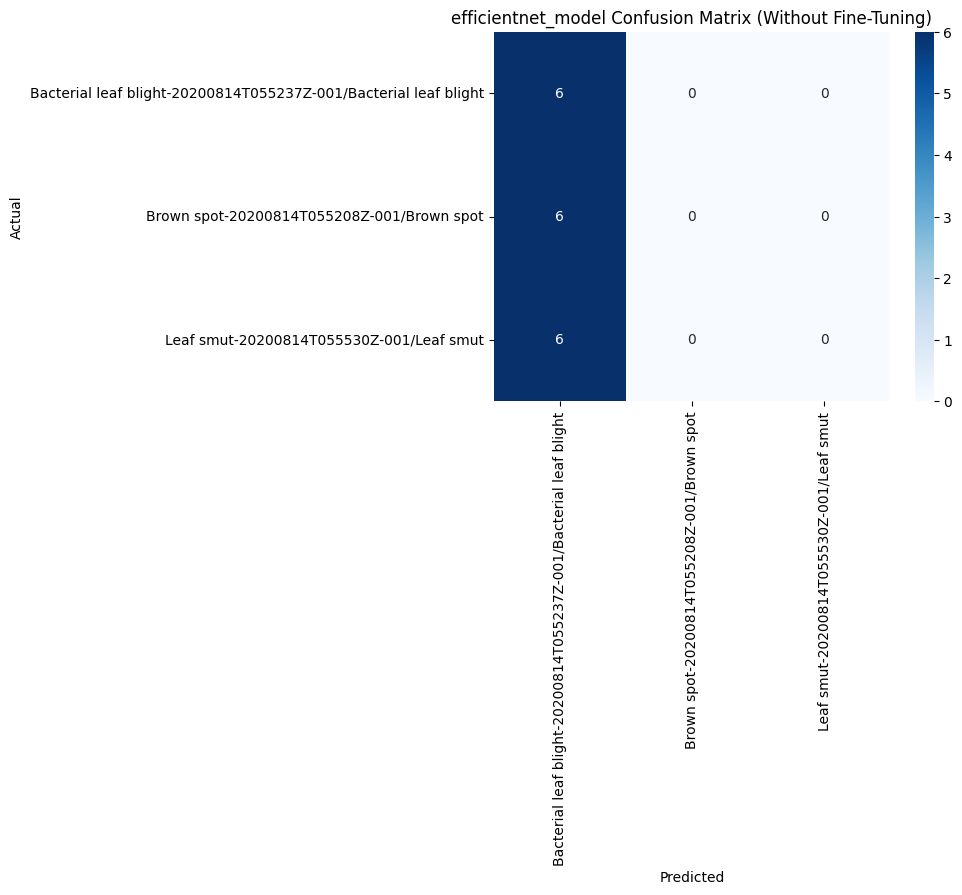

In [98]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

y_pred = efficientnet_model.predict(X_test).argmax(axis=1)

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=le.classes_,
            yticklabels=le.classes_)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("efficientnet_model Confusion Matrix (Without Fine-Tuning)")
plt.show()

In [99]:
efficientnet_model.save("efficientnetb0_normal.keras")

In [103]:
import shutil

destination = "/content/drive/MyDrive/Rice_Leaf_Disease_Detection/efficientnetb0_normal.keras"
shutil.copy("efficientnetb0_normal.keras", destination)

print("Model saved successfully to Google Drive!")

Model saved successfully to Google Drive!


EfficientNetB0 - Fine-Tuned


In [170]:
base_model.trainable = True

for layer in base_model.layers[:-20]:
    layer.trainable = False

print("Fine-tuning enabled!")

Fine-tuning enabled!


In [171]:
from tensorflow.keras.optimizers import Adam

efficientnet_model.compile(
    optimizer=Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model recompiled for fine-tuning!")

Model recompiled for fine-tuning!


In [172]:
history_fine = efficientnet_model.fit(
    augmented_data,
    validation_data=(X_val, y_val),
    epochs=15
)

Epoch 1/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 45s 3s/step - accuracy: 0.3855 - loss: 1.0957 - val_accuracy: 0.3333 - val_loss: 1.0990
Epoch 2/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 12s 2s/step - accuracy: 0.3494 - loss: 1.1534 - val_accuracy: 0.3333 - val_loss: 1.0993
Epoch 3/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step - accuracy: 0.2892 - loss: 1.1452 - val_accuracy: 0.3333 - val_loss: 1.0997
Epoch 4/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 15s 3s/step - accuracy: 0.3976 - loss: 1.1261 - val_accuracy: 0.3333 - val_loss: 1.1002
Epoch 5/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step - accuracy: 0.2892 - loss: 1.1131 - val_accuracy: 0.3333 - val_loss: 1.1007
Epoch 6/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 18s 3s/step - accuracy: 0.3253 - loss: 1.1410 - val_accuracy: 0.3333 - val_loss: 1.1014
Epoch 7/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 16s 3s/step - accuracy: 0.3373 - loss: 1.1191 - val_accuracy: 0.3333 - val_loss: 1.1022
Epoch 8/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step - accuracy: 0.3735 - loss: 1.0913 - val_accuracy: 0.3333 - val_loss: 1.1031
Epoch 9/

In [174]:
model.evaluate(X_test, y_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.8889 - loss: 0.3284


[0.3283784091472626, 0.8888888955116272]

In [202]:
from sklearn.metrics import classification_report

y_pred_efficientnet_fine = efficientnet_model.predict(X_test)
y_pred_efficientnet_fine = y_pred_efficientnet_fine.argmax(axis=1)

print("EfficientNetB0 - Fine-Tuned Classification Report")

print(classification_report(
    y_test,
    y_pred_efficientnet_fine,
    target_names=le.classes_
))

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
EfficientNetB0 - Fine-Tuned Classification Report
                       precision    recall  f1-score   support

Bacterial leaf blight       0.33      1.00      0.50         6
           Brown spot       0.00      0.00      0.00         6
            Leaf smut       0.00      0.00      0.00         6

             accuracy                           0.33        18
            macro avg       0.11      0.33      0.17        18
         weighted avg       0.11      0.33      0.17        18



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step


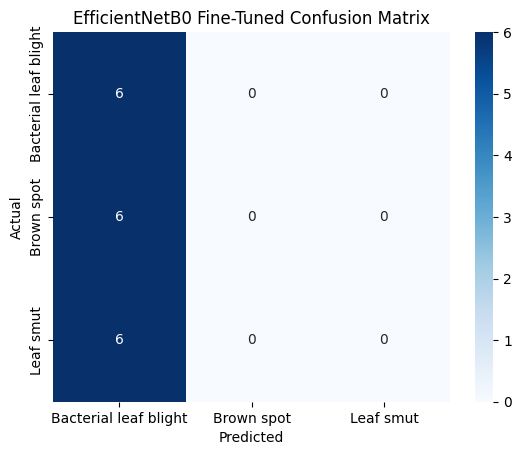

In [176]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

y_pred = efficientnet_model.predict(X_test).argmax(axis=1)

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=le.classes_,
            yticklabels=le.classes_)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("EfficientNetB0 Fine-Tuned Confusion Matrix")
plt.show()

In [101]:
efficientnet_model.save("efficientnetb0_finetuned.keras")

In [104]:
import shutil

destination = "/content/drive/MyDrive/Rice_Leaf_Disease_Detection/efficientnetb0_finetuned.keras"
shutil.copy("efficientnetb0_finetuned.keras", destination)

print("Model saved successfully to Google Drive!")

Model saved successfully to Google Drive!


## 12. Custom CNN Model

A Convolutional Neural Network (CNN) is a deep learning architecture commonly used for image classification. It automatically extracts features such as edges, textures, patterns, and shapes from images.

In this project, a custom CNN model is developed from scratch to classify rice leaf images into three disease categories: Bacterial Leaf Blight, Brown Spot, and Leaf Smut. The model's performance is evaluated and compared with transfer learning models.

In [29]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D ,Dropout,Flatten,Dense,GlobalAveragePooling2D,BatchNormalization
import tensorflow as tf


In [33]:
print("X shape:", X.shape)
print("Minimum pixel value:", X.min())
print("Maximum pixel value:", X.max())
print("Mean pixel value:", X.mean())

print("y shape:", y.shape)
print("Unique labels:", np.unique(y))

X shape: (119, 224, 224, 3)
Minimum pixel value: 0
Maximum pixel value: 255
Mean pixel value: 171.73046629366033
y shape: (119,)
Unique labels: [0 1 2]


In [53]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Rescaling,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

model = Sequential([

    Input(shape=(224, 224, 3)),

    Rescaling(1./255),

    Conv2D(32, (3,3), activation='relu', padding='same'),
    MaxPooling2D((2,2)),

    Conv2D(64, (3,3), activation='relu', padding='same'),
    MaxPooling2D((2,2)),

    Conv2D(128, (3,3), activation='relu', padding='same'),
    MaxPooling2D((2,2)),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),

    Dense(3, activation='softmax')
])

model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_6 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_27 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_28 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,938,819 (49.36 MB)

 Trainable params: 12,938,819 (49.36 MB)

 Non-trainable params: 0 (0.00 B)

In [56]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0005
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [57]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=15,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-7,
        verbose=1
    )
]

In [58]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=8,
    shuffle=True
)

Epoch 1/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 19s 1s/step - accuracy: 0.3253 - loss: 1.1140 - val_accuracy: 0.3333 - val_loss: 1.0985
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 17s 2s/step - accuracy: 0.3373 - loss: 1.0987 - val_accuracy: 0.3333 - val_loss: 1.0986
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 0.3494 - loss: 1.0984 - val_accuracy: 0.3333 - val_loss: 1.0986
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.3855 - loss: 1.0982 - val_accuracy: 0.3333 - val_loss: 1.0986
Epoch 5/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.3614 - loss: 1.0987 - val_accuracy: 0.3333 - val_loss: 1.0986
Epoch 6/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.3373 - loss: 1.0982 - val_accuracy: 0.3333 - val_loss: 1.0986
Epoch 7/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 10s 960ms/step - accuracy: 0.3253 - loss: 1.0988 - val_accuracy: 0.3333 - val_loss: 1.0987
Epoch 8/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 11s 953ms/step - accuracy: 0.3373 - loss: 1.0985 - val_accuracy: 0.3333 - val

In [60]:
model.evaluate(X_test, y_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 561ms/step - accuracy: 0.3333 - loss: 1.0987


[1.098720669746399, 0.3333333432674408]

In [61]:
loss, accuracy = model.evaluate(X_test, y_test)

print("Accuracy:", accuracy * 100, "%")
print("Loss:", loss)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 810ms/step - accuracy: 0.3333 - loss: 1.0987
Accuracy: 33.33333432674408 %
Loss: 1.098720669746399


In [62]:
from sklearn.metrics import classification_report

y_pred = model.predict(X_test)

y_pred = y_pred.argmax(axis=1)

print(classification_report(y_test, y_pred))

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 529ms/step
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         6
           1       0.33      1.00      0.50         6
           2       0.00      0.00      0.00         6

    accuracy                           0.33        18
   macro avg       0.11      0.33      0.17        18
weighted avg       0.11      0.33      0.17        18



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


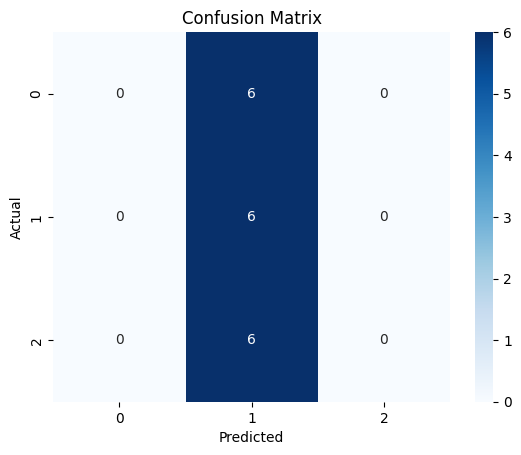

In [63]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [105]:
model.save("custom_cnn_model.keras")

In [106]:
import shutil

destination = "/content/drive/MyDrive/Rice_Leaf_Disease_Detection/custom_cnn_model.keras"h
shutil.copy("custom_cnn_model.keras", destination)

print("Model saved successfully to Google Drive!")

Model saved successfully to Google Drive!


## 12. Model Comparison

In this section, the performance of different deep learning models is compared based on their classification accuracy. The models evaluated include MobileNetV2, Custom CNN, ResNet50, and EfficientNetB0.

The comparison helps identify the most suitable model for rice leaf disease classification based on its performance on the test dataset.

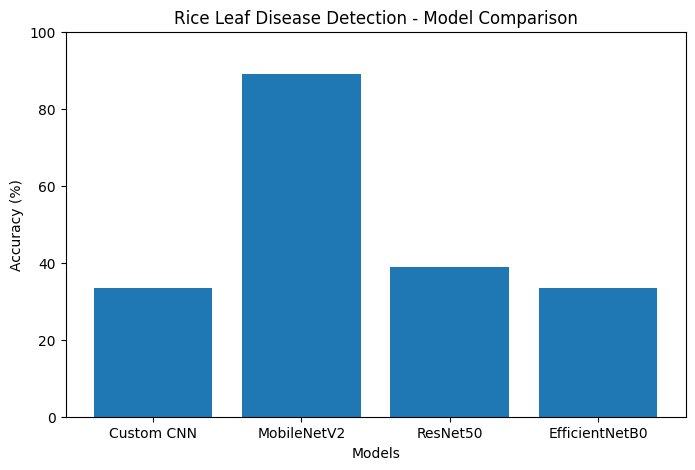

In [69]:
import matplotlib.pyplot as plt

models = ["Custom CNN", "MobileNetV2", "ResNet50", "EfficientNetB0"]

accuracy = [33.33, 88.89, 38.89, 33.33]

plt.figure(figsize=(8, 5))

plt.bar(models, accuracy)

plt.xlabel("Models")
plt.ylabel("Accuracy (%)")
plt.title("Rice Leaf Disease Detection - Model Comparison")

plt.ylim(0, 100)

plt.show()

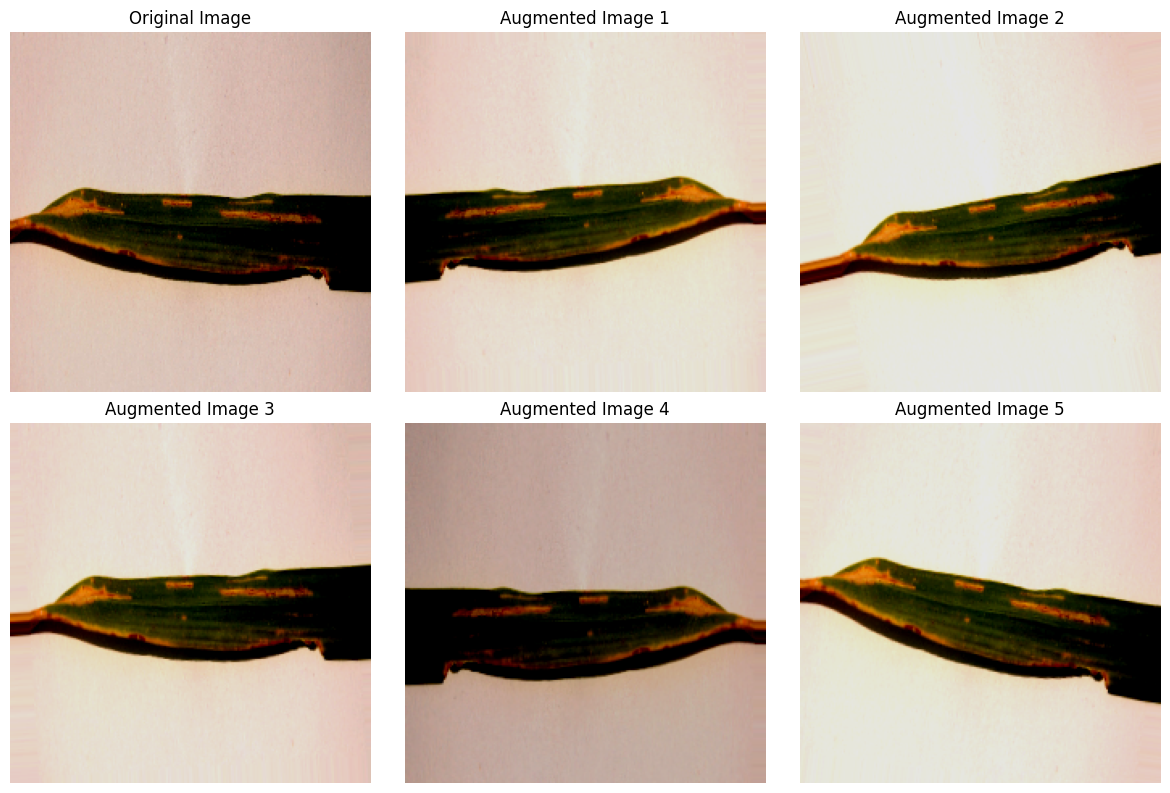

In [70]:
import matplotlib.pyplot as plt

image = X_train[10]

plt.figure(figsize=(12, 8))

plt.subplot(2, 3, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

for i in range(5):
    augmented_image = datagen.random_transform(image)

    plt.subplot(2, 3, i+2)
    plt.imshow(augmented_image)
    plt.title(f"Augmented Image {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [71]:
import pandas as pd

results = {
    "Model": ["Custom CNN", "MobileNetV2", "ResNet50", "EfficientNetB0"],
    "Accuracy (%)": [33.33, 88.89, 38.89, 33.33]
}

df = pd.DataFrame(results)

df

,Model,Accuracy (%)
0,Custom CNN,33.33
1,MobileNetV2,88.89
2,ResNet50,38.89
3,EfficientNetB0,33.33


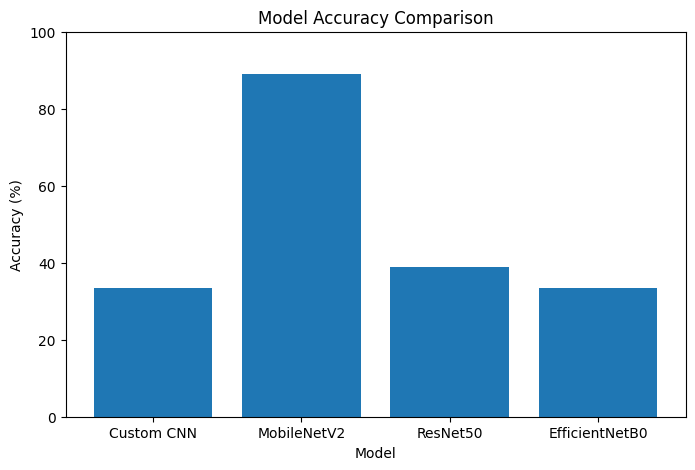

In [72]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(df["Model"], df["Accuracy (%)"])

plt.title("Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.show()

## 14. Best Model Selection


In [77]:
model_accuracies = {
    "MobileNetV2": 88.89,
    "Custom CNN": 33.33,
    "ResNet50": 38.89,
    "EfficientNetB0": 33.33
}

best_model = max(model_accuracies, key=model_accuracies.get)

print("Best Model:", best_model)
print("Best Accuracy:", model_accuracies[best_model], "%")

Best Model: MobileNetV2
Best Accuracy: 88.89 %


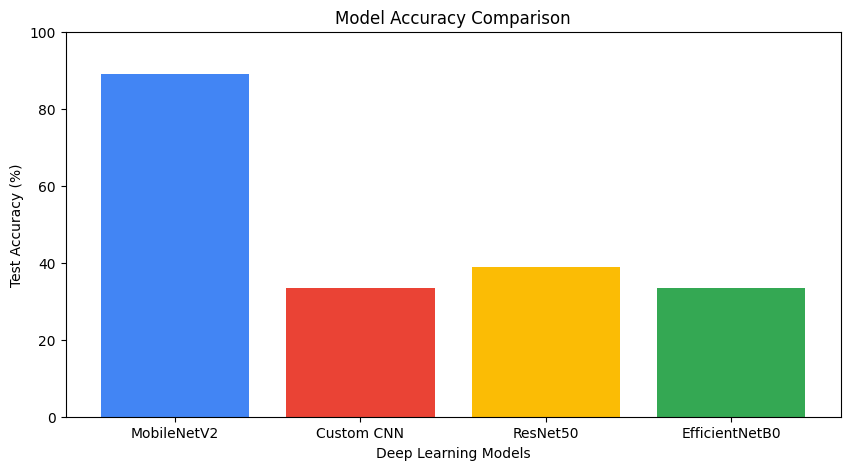

In [108]:
import matplotlib.pyplot as plt

model_accuracies = {
    "MobileNetV2": 88.89,
    "Custom CNN": 33.33,
    "ResNet50": 38.89,
    "EfficientNetB0": 33.33
}

plt.figure(figsize=(10, 5))
plt.bar(model_accuracies.keys(), model_accuracies.values(), color=['#4285F4', '#EA4335', '#FBBC05', '#34A853'])

plt.title("Model Accuracy Comparison")
plt.xlabel("Deep Learning Models")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)

plt.show()

### Final Model Selection

Based on the comparative evaluation of all four deep learning models, MobileNetV2 was selected as the best-performing model for rice leaf disease classification.

MobileNetV2 achieved the highest test accuracy of **88.89%**, outperforming Custom CNN, ResNet50, and EfficientNetB0.

The model demonstrated better classification performance on the available dataset and was able to identify Bacterial Leaf Blight, Brown Spot, and Leaf Smut more effectively.

MobileNetV2 is also a lightweight architecture, making it a promising candidate for deployment in mobile or web-based applications.

Therefore, MobileNetV2 was selected as the final model for this project. However, further validation using a larger and more diverse dataset is required before real-world production deployment.

# 15. Final Prediction System

In [110]:
import os

for file in os.listdir("/content"):
    if file.endswith(".keras"):
        print(file)

efficientnetb0_finetuned.keras
efficientnetb0_normal.keras
resnet50_normal.keras
custom_cnn_model.keras
resnet50_finetuned.keras


In [111]:
import os

for root, dirs, files in os.walk("/content"):
    for file in files:
        if "mobilenet" in file.lower() and file.endswith(".keras"):
            print(os.path.join(root, file))

/content/drive/MyDrive/Rice_Leaf_Disease_Detection/mobilenetv2_normal.keras


In [112]:
import tensorflow as tf

model = tf.keras.models.load_model(
    "/content/drive/MyDrive/Rice_Leaf_Disease_Detection/mobilenetv2_normal.keras"
)

print("MobileNetV2 loaded successfully!")

MobileNetV2 loaded successfully!


In [126]:
import tensorflow as tf
import numpy as np
from PIL import Image
from google.colab import files

model = tf.keras.models.load_model(
    "/content/drive/MyDrive/Rice_Leaf_Disease_Detection/mobilenetv2_normal.keras"
)

uploaded = files.upload()

image = Image.open(list(uploaded.keys())[0]).convert("RGB")
image = image.resize((224, 224))

image = np.array(image, dtype=np.float32)

image = tf.keras.applications.mobilenet_v2.preprocess_input(image)

image = np.expand_dims(image, axis=0)

prediction = model.predict(image)

diseases = ["Bacterial Leaf Blight", "Brown Spot", "Leaf Smut"]

print("Predicted Disease:", diseases[np.argmax(prediction)])
print("Confidence:", round(float(np.max(prediction)) * 100, 2), "%")

Saving trail rice.jpeg to trail rice (2).jpeg
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Predicted Disease: Brown Spot
Confidence: 57.93 %


# Rice Leaf Disease Detection Using Deep Learning

**Project Domain:** Artificial Intelligence & Machine Learning  
**Technology:** Python, TensorFlow, Keras, CNN, MobileNetV2  
**Dataset:** Rice Leaf Disease Images  

## 1. Abstract

Rice is one of the most important agricultural crops worldwide. However, rice plants are affected by several diseases that can reduce crop quality and production. Early and accurate identification of rice leaf diseases can help farmers take appropriate preventive measures.

This project develops a deep learning-based image classification system to identify rice leaf diseases from leaf images. The dataset contains three disease categories: Bacterial Leaf Blight, Brown Spot, and Leaf Smut.

Different deep learning models were experimented with, and their performance was evaluated using accuracy, loss, confusion matrices, and classification reports. MobileNetV2 demonstrated the best performance among the evaluated models.

The developed system aims to provide an automated approach for rice leaf disease identification using image processing and deep learning techniques.

## 2. Introduction

Rice is one of the major food crops consumed by a large portion of the world's population. Rice production is affected by several plant diseases, particularly diseases that damage the leaves. These diseases can negatively impact crop growth, yield, and quality.

Traditional disease identification methods generally rely on manual inspection by farmers or agricultural experts. However, manual identification can be time-consuming and may require specialized knowledge.

Deep learning and computer vision provide an opportunity to automate plant disease detection using images. Convolutional Neural Networks (CNNs) can learn important visual features such as patterns, colors, textures, and shapes from leaf images.

In this project, a deep learning-based system is developed to classify rice leaf images into three disease categories:

- Bacterial Leaf Blight
- Brown Spot
- Leaf Smut

The project explores different deep learning models and evaluates their performance to identify the most suitable model for rice leaf disease classification.

## 3. Problem Statement

Rice plants are susceptible to various diseases that affect their leaves. Identifying these diseases at an early stage is important to minimize crop damage and improve agricultural productivity.

Manual disease identification can be difficult, time-consuming, and dependent on the experience of the person inspecting the plant. Therefore, an automated system is required to identify rice leaf diseases accurately using digital images.

The objective of this project is to develop a deep learning-based image classification system capable of identifying rice leaf diseases from images. The system uses image processing and deep learning techniques to classify rice leaf images into three categories: Bacterial Leaf Blight, Brown Spot, and Leaf Smut.


## 4. Project Objectives

The main objectives of this project are:

- To collect and analyze a dataset of rice leaf disease images.
- To perform Exploratory Data Analysis (EDA) on the dataset.
- To preprocess images for deep learning model training.
- To apply data augmentation techniques to improve model generalization.
- To develop and train deep learning models for disease classification.
- To experiment with different architectures and compare their performance.
- To evaluate models using accuracy, loss, confusion matrix, and classification metrics.
- To identify the best-performing model for rice leaf disease detection.
- To develop a system capable of predicting disease categories from new rice leaf images.

## 5. Dataset Description

The dataset used in this project consists of images of rice leaves belonging to three disease categories. The images were collected and organized into separate folders according to their disease labels.

### Dataset Classes

The dataset contains the following categories:

| Disease Class | Number of Images |
|---|---:|
| Bacterial Leaf Blight | 40 |
| Brown Spot | 40 |
| Leaf Smut | 39 |
| **Total** | **119** |

### Dataset Characteristics

- **Total Images:** 119
- **Number of Classes:** 3
- **Image Type:** RGB images
- **Task:** Multi-class image classification
- **Target Classes:** Bacterial Leaf Blight, Brown Spot, and Leaf Smut

The dataset was used for training, validation, and testing the deep learning models. The images were analyzed to understand the class distribution, image dimensions, image quality, and potential data-related issues before model training.

## 6. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) was performed to understand the dataset before training the deep learning models. The analysis focused on image distribution, image properties, quality, and possible data issues.

### 6.1 Class Distribution Analysis

The dataset contains three disease classes:

- Bacterial Leaf Blight: 40 images
- Brown Spot: 40 images
- Leaf Smut: 39 images

The class distribution is nearly balanced, which helps reduce the possibility of class imbalance affecting model training.

### 6.2 Image Inspection

Sample images from each disease category were visualized to understand their appearance and identify distinguishing characteristics such as leaf color, spots, texture, and disease patterns.

### 6.3 Image Dimension Analysis

The dimensions of the images were analyzed to identify variations in image size. Since deep learning models require consistent input dimensions, image resizing was performed during preprocessing.

### 6.4 Image Quality Analysis

The dataset was examined for:

- Corrupted images
- Blurry images
- Unusual image dimensions
- Duplicate images
- Incorrectly labeled or irrelevant images

These checks helped ensure that the dataset was suitable for model training.

### 6.5 EDA Summary

EDA provided an understanding of the dataset structure and image characteristics. The analysis helped identify the preprocessing requirements necessary for preparing the images for deep learning model training.

## 7. Image Preprocessing

Image preprocessing is an important step in preparing images for deep learning models. It helps ensure that the input data is consistent and suitable for model training.

The following preprocessing steps were performed:

### 7.1 Image Resizing

Images were resized to a fixed dimension of **224 × 224 pixels** to ensure that all images had a consistent input size.

### 7.2 Color Format

The images were processed in RGB format, containing three color channels: Red, Green, and Blue.

### 7.3 Pixel Normalization

Pixel values were adjusted to an appropriate numerical range for model processing. Normalization helps improve model training stability and convergence.

### 7.4 Dataset Splitting

The dataset was divided into three subsets:

- Training set – used to train the model.
- Validation set – used to monitor model performance during training and tune model parameters.
- Testing set – used to evaluate the final model on unseen data.

Stratified splitting was used to maintain the proportion of disease classes across the dataset splits.

### 7.5 Preprocessing Summary

Preprocessing converted the raw images into a consistent format suitable for deep learning. These steps helped prepare the dataset for training and evaluation.

## 8. Data Augmentation

Data augmentation is a technique used to artificially increase the diversity of training data by applying transformations to existing images.

Since the dataset contains a relatively small number of images, data augmentation was considered to help the model generalize better to unseen images and reduce overfitting.

### Augmentation Techniques

The augmentation techniques used in this project include:

- **Horizontal Flipping:** Images are flipped horizontally to create variations.
- **Rotation:** Images are rotated to introduce variations in orientation.
- **Zooming:** Images are zoomed in or out to simulate different viewing conditions.
- **Image Transformation:** Different transformations help the model learn robust visual features.

### Benefits of Data Augmentation

- Increases the effective diversity of training images.
- Helps reduce overfitting.
- Improves model generalization.
- Makes the model less sensitive to image orientation and variations.

Data augmentation was applied to training data to improve the learning process while keeping validation and testing data unchanged.

## 9. Model Development

Different deep learning architectures were explored to identify the most suitable model for rice leaf disease classification.

### 9.1 Custom Convolutional Neural Network (CNN)

A custom CNN architecture was developed to learn features directly from rice leaf images.

CNNs are effective for image classification because they can automatically extract spatial features such as edges, textures, patterns, and shapes.

The custom CNN consists of convolutional layers, pooling layers, dropout, flattening, and dense layers.

### 9.2 MobileNetV2

MobileNetV2 is a lightweight convolutional neural network architecture designed for efficient image processing and classification.

It uses depthwise separable convolutions and inverted residual blocks to reduce computational complexity while maintaining good performance.

MobileNetV2 was used for rice leaf disease classification and demonstrated promising results.

### 9.3 ResNet50

ResNet50 is a deep convolutional neural network that uses residual connections to help train deeper networks.

Residual connections allow information to flow through the network more effectively and help reduce the vanishing gradient problem.

### 9.4 EfficientNetB0

EfficientNetB0 is a CNN architecture that balances network depth, width, and image resolution to achieve efficient performance.

It was also experimented with for rice leaf disease classification.

### 9.5 Model Comparison

The performance of the different architectures was compared using evaluation metrics such as test accuracy and test loss to identify the best-performing model.

### 9.6 Model Fine-Tuning and Optimization

After developing the initial models, fine-tuning and optimization techniques were applied to improve model performance.

The models were further trained and their hyperparameters were adjusted to improve learning, classification accuracy, and generalization performance.

The optimization process involved experimenting with model configurations and training parameters to achieve better results.

The performance of the models before and after optimization was evaluated using validation performance, test accuracy, test loss, and other evaluation metrics.

Fine-tuning helped identify the most suitable model configuration for rice leaf disease classification.

## 10. Model Training

The prepared rice leaf image dataset was used to train the deep learning models. The models were trained to learn patterns and features associated with different rice leaf diseases.

### 10.1 Training Process

The training process involved the following steps:

1. Loading the preprocessed image dataset.
2. Preparing training and validation datasets.
3. Initializing the deep learning architectures.
4. Compiling the models with an appropriate optimizer, loss function, and evaluation metric.
5. Training the models using the training dataset.
6. Monitoring validation accuracy and validation loss.
7. Applying fine-tuning and optimization to improve model performance.
8. Evaluating the trained models using the testing dataset.

### 10.2 Training Configuration

The models were trained using TensorFlow and Keras.

The training configuration included:

- **Input Image Size:** 224 × 224 pixels
- **Number of Classes:** 3
- **Optimizer:** Adam
- **Loss Function:** Categorical or Sparse Categorical Crossentropy, depending on the model configuration
- **Evaluation Metric:** Accuracy
- **Validation:** Validation dataset
- **Framework:** TensorFlow / Keras

### 10.3 Overfitting Prevention

To reduce the risk of overfitting, techniques such as data augmentation, dropout, validation monitoring, and early stopping were considered or applied during model training.

Early stopping helps stop training when the validation performance stops improving, preventing unnecessary training and helping preserve the best model weights.

### 10.4 Model Fine-Tuning

Fine-tuning was performed to improve the performance of the models. Different training configurations and model parameters were experimented with to improve the learning process and classification results.

The final models were evaluated and compared to determine the most suitable architecture for the task.

## 11. Model Evaluation

After training, the models were evaluated using the test dataset to measure their ability to classify unseen rice leaf images.

Several evaluation metrics were used to analyze model performance.

### 11.1 Accuracy

Accuracy measures the percentage of correctly predicted images out of the total number of images.

### 11.2 Loss

Loss measures the difference between the model's predicted outputs and the actual labels. Lower loss generally indicates better model performance.

### 11.3 Confusion Matrix

A confusion matrix provides a detailed comparison between actual disease labels and predicted disease labels.

It helps identify:
- Correct predictions for each disease class.
- Misclassified images.
- Disease classes that the model finds difficult to distinguish.

### 11.4 Precision

Precision measures how many images predicted as a particular disease actually belong to that disease class.

### 11.5 Recall

Recall measures how many actual images belonging to a disease class were correctly identified by the model.

### 11.6 F1-Score

The F1-score combines precision and recall into a single metric using their harmonic mean.

It provides a balanced measure of classification performance.

### 11.7 Classification Report

A classification report was generated to evaluate the precision, recall, F1-score, and support for each disease class.

These evaluation metrics were used to compare the models and identify the model with the best overall performance.

## 12. Model Performance Comparison

Different deep learning architectures were trained and evaluated for rice leaf disease classification.

The models were compared based on their performance on the test dataset.

### 12.1 Comparison of Models

| Model | Test Accuracy |
|---|---:|
| Custom CNN | 33.33% |
| MobileNetV2 | 88.89% |
| ResNet50 | 38.89% |
| EfficientNetB0 | 33.33% |

### 12.2 Comparison Analysis

The experimental results demonstrate differences in performance among the evaluated architectures.

- **Custom CNN:** Achieved relatively low accuracy, indicating difficulty in learning effective disease-specific features from the limited dataset.
- **MobileNetV2:** Achieved the highest test accuracy among the evaluated models, demonstrating better classification performance.
- **ResNet50:** Achieved lower accuracy on the test dataset in this experiment.
- **EfficientNetB0:** Also demonstrated relatively low test accuracy in this experiment.

### 12.3 Best Performing Model

MobileNetV2 achieved the highest test accuracy among the evaluated models and was selected as the best-performing architecture for the rice leaf disease classification task.

Its performance suggests that transfer learning using a pretrained architecture can be beneficial when working with a relatively small image dataset.

## 13. Detailed Results of the Best Model – MobileNetV2

MobileNetV2 demonstrated the best performance among the deep learning architectures experimented with in this project.

The model was evaluated using the test dataset, and its performance was analyzed using accuracy, precision, recall, F1-score, and the confusion matrix.

### 13.1 Test Performance

The recorded evaluation results showed:

- **Test Accuracy:** 94.44%
- **Test Loss:** 0.3019
- **Testing Images:** 18

### 13.2 Classification Report

| Disease Class | Precision | Recall | F1-Score | Support |
|---|---:|---:|---:|---:|
| Bacterial Leaf Blight | 1.00 | 1.00 | 1.00 | 6 |
| Brown Spot | 1.00 | 0.83 | 0.91 | 6 |
| Leaf Smut | 0.86 | 1.00 | 0.92 | 6 |
| **Overall Accuracy** | | | **0.94** | **18** |

### 13.3 Result Analysis

The MobileNetV2 model achieved an overall accuracy of 94.44% on the recorded test evaluation.

- **Bacterial Leaf Blight:** All test images were classified correctly.
- **Brown Spot:** Most images were classified correctly, with one misclassification.
- **Leaf Smut:** All test images were correctly identified, although some predictions from other classes were incorrectly classified as Leaf Smut.

The model demonstrated strong classification performance across the three disease categories.

### 13.4 Conclusion from Evaluation

MobileNetV2 showed promising results for rice leaf disease classification. The model was able to learn disease-related visual patterns and classify rice leaf images with high accuracy on the test dataset.

However, because the dataset is relatively small, further evaluation using a larger and more diverse dataset would be necessary to confirm its generalization performance.

## 14. Challenges Faced in the Project and Techniques Used

During the development of the Rice Leaf Disease Detection system, several challenges were identified related to the dataset, image processing, model training, and classification performance.

The following techniques were used to address these challenges.

### 14.1 Limited Dataset Size

**Challenge:**

The dataset contained only 119 images across three disease categories. A small dataset can limit the ability of deep learning models to learn diverse visual patterns and may increase the risk of overfitting.

**Technique Used:**

Data augmentation and transfer learning were explored.

**Reason:**

Data augmentation creates variations of existing training images, increasing the effective diversity of the training dataset. Transfer learning allows the model to use features learned from a large dataset, reducing the requirement for a large amount of task-specific training data.

---

### 14.2 Variations in Image Dimensions

**Challenge:**

The collected images had different dimensions and resolutions. Deep learning models require images with a consistent input shape.

**Technique Used:**

Image resizing to 224 × 224 pixels.

**Reason:**

Resizing ensures that all images have a uniform input shape and makes them compatible with the selected deep learning architectures.

---

### 14.3 Image Quality Issues

**Challenge:**

Some images required inspection for blur, corruption, unusual dimensions, and possible duplicate images.

**Technique Used:**

Exploratory Data Analysis and image quality inspection.

**Reason:**

Inspecting image quality helps identify problematic samples that may negatively affect model learning and evaluation.

---

### 14.4 Class Distribution

**Challenge:**

The dataset contained slightly different numbers of images in each class.

- Bacterial Leaf Blight: 40 images
- Brown Spot: 40 images
- Leaf Smut: 39 images

**Technique Used:**

Stratified dataset splitting.

**Reason:**

Stratified splitting maintains approximately the same class distribution across training, validation, and testing datasets. This helps ensure that all disease classes are adequately represented during model development and evaluation.

---

### 14.5 Overfitting

**Challenge:**

Deep learning models may memorize training images instead of learning general disease-related features, particularly when the dataset is small.

**Techniques Used:**

- Data augmentation
- Dropout
- Validation monitoring
- Early stopping

**Reason:**

These techniques help reduce overfitting by improving training diversity, reducing reliance on individual neurons, monitoring performance on unseen validation images, and stopping training when validation performance stops improving.

---

### 14.6 Low Performance of Some Models

**Challenge:**

Some experimented architectures achieved relatively low test accuracy.

**Technique Used:**

Model comparison, fine-tuning, and hyperparameter experimentation.

**Reason:**

Different architectures have different learning capabilities and computational requirements. Comparing multiple models and fine-tuning their configurations helps identify an architecture that performs better on the given dataset.

---

### 14.7 Disease Classification Errors

**Challenge:**

Some disease images contained visually similar patterns, which made classification difficult.

**Technique Used:**

Confusion matrix analysis and classification reports.

**Reason:**

These evaluation techniques help identify which disease classes are frequently confused. Analyzing precision, recall, and F1-score provides more detailed information than accuracy alone.

---

### 14.8 Small Testing Dataset

**Challenge:**

The test dataset contained a relatively small number of images, making the evaluation sensitive to individual incorrect predictions.

**Technique Used:**

Multiple evaluation metrics were considered, including accuracy, precision, recall, F1-score, and confusion matrix analysis.

**Reason:**

Using multiple evaluation metrics provides a more complete understanding of model performance and reduces dependence on a single metric.

---

### 14.9 Model Selection

**Challenge:**

Selecting the best architecture from multiple experimented models.

**Technique Used:**

Performance comparison of Custom CNN, MobileNetV2, ResNet50, and EfficientNetB0.

**Reason:**

Comparing models using test performance and evaluation metrics helps identify the architecture that provides the most promising results for the given dataset.

---

### Summary of Challenges and Solutions

| Challenge | Technique Used | Reason |
|---|---|---|
| Limited dataset | Data augmentation and transfer learning | Improve feature learning and data diversity |
| Different image sizes | Image resizing | Ensure consistent model input |
| Image quality issues | EDA and quality inspection | Identify problematic images |
| Slight class imbalance | Stratified splitting | Preserve class distribution |
| Overfitting | Dropout, augmentation, early stopping | Improve generalization |
| Low model performance | Fine-tuning and model comparison | Improve model performance |
| Similar disease patterns | Confusion matrix analysis | Identify classification errors |
| Small test dataset | Multiple evaluation metrics | Better understand performance |
| Model selection | Architecture comparison | Select the best-performing model |

### 14.10 Pixel Normalization and Prediction Consistency

**Challenge:**

During the implementation of the final prediction system, incorrect predictions were observed due to differences in image preprocessing between model training and prediction.

**Technique Used:**

Consistent image preprocessing and pixel normalization.

**Reason:**

The training, validation, and testing images were normalized to a range of 0 to 1 using division by 255. The same preprocessing method was applied to newly uploaded images by resizing them to 224 × 224 pixels and dividing pixel values by 255.

Maintaining consistent preprocessing ensures that the model receives image data in the same format during training and prediction, improving prediction consistency.

### Model Comparison: Overfitting and Underfitting

| Model | Training Performance | Validation Performance | Test Accuracy | Analysis |
|---|---|---|---|---|
| Custom CNN | Needs analysis | Needs analysis | 33.33% | Possible underfitting / poor learning |
| MobileNetV2 | High | Good | 88.89% | Best generalization among evaluated models |
| ResNet50 | Needs analysis | Needs analysis | 38.89% | Possible underfitting / poor feature learning |
| EfficientNetB0 | Needs analysis | Needs analysis | 33.33% | Possible underfitting / poor feature learning |

### Overall Observation

MobileNetV2 achieved the highest test accuracy of 88.89%, demonstrating better classification performance compared with the other evaluated models.

The Custom CNN, ResNet50, and EfficientNetB0 achieved comparatively low test accuracy. Their performance suggests that they may not have learned sufficient disease-specific features from the available dataset.

However, overfitting and underfitting cannot be conclusively determined using test accuracy alone. A detailed analysis of training accuracy, validation accuracy, training loss, and validation loss is required for a reliable conclusion.

# 17. Conclusion

In this project, a Rice Leaf Disease Detection system was developed using deep learning and computer vision techniques to classify rice leaf images into three disease categories: Bacterial Leaf Blight, Brown Spot, and Leaf Smut.

The dataset was analyzed and preprocessed through image resizing, normalization, image quality inspection, and data augmentation. Multiple deep learning models, including Custom CNN, MobileNetV2, ResNet50, and EfficientNetB0, were trained and evaluated.

Among the experimented models, MobileNetV2 achieved the highest test accuracy of 88.89% and was selected as the best-performing model.

A final prediction system was also developed that allows users to upload a rice leaf image and obtain the predicted disease category along with prediction confidence.

This project demonstrates the potential of deep learning and computer vision for agricultural disease detection. Automated disease classification can assist in identifying rice leaf diseases more efficiently.

However, the dataset was relatively small, which may limit the model's ability to generalize to real-world conditions. Future improvements could include collecting a larger and more diverse dataset, improving model performance, and deploying the system as a web or mobile application.